# 2_treino_cnn - treino, calibração e avaliação da CNN (CPU)

Treina a CNN com o conjunto do `0b_conjunto_treino` e as **mesmas divisões do `1_baselines`**: teste = fold *f*, validação = fold *f* + 1, treino = os outros três folds, com os folds formados por órbitas-ponto.

**Rede.** CNN rasa:

```
Conv 3×3 (32) → BatchNorm → ReLU → Conv 3×3 (64) → BatchNorm → ReLU → Flatten → Dropout → Linear (4 classes)
```

As convoluções usam *padding*, então o mapa mantém o tamanho do patch. O `Flatten` preserva a posição de cada pixel na janela, o que importa porque o rótulo é o do **pixel central**.

**Treino.**
- Perda de entropia cruzada ponderada pelo inverso da frequência das classes no treino: a saída corresponde a probabilidades com classes equiprováveis, como no MaxVer e no RF do `1_baselines`.
- *Data augmentation* sorteado a cada lote: uma das 8 simetrias do quadrado por patch e, nas cópias transformadas, variação radiométrica leve (ganho e deslocamento por banda).
- Parada antecipada pela NLL balanceada na validação; o melhor modelo é restaurado.

**Tamanho do patch.** O 0b grava patches 9 × 9; a CNN usa o recorte central de `TAMANHO_PATCH` (5, 7 ou 9). Cada tamanho é um experimento, com a sua subpasta (`NOME_EXPERIMENTO`): para cada experimento é necessário rodar o notebook uma vez. A seção 6 compara os experimentos pela validação; a seção 4 compara a CNN com o RF com contexto da **mesma janela**, divisão a divisão.

**Outras observações.** Conjunto e folds do 0b (TerraClass 2008/2010 do Pará, órbitas-ponto); 4 classes, todas possíveis em todas as datas; escala fixa do 0b; bandas escolhidas em `BANDAS_USADAS`; previsão fora do fold da repetição 0, como no `1_baselines`.

Lê só `resultados\0b_conjunto_treino\<NOME_CONJUNTO>\` e `resultados\1_baselines\<EXPERIMENTO_BASELINES>\`; grava só em `resultados\2_treino_cnn\<NOME_EXPERIMENTO>\`.

Obs.: Documentação do Código feita com auxílio de IA (Claude Opus 5.5)

## Seleção dos parâmetros da CNN

Os valores abaixo definem a arquitetura, o treinamento e a avaliação. Os valores iniciais são uma configuração de referência; devem ser ajustados com base na **validação**, sem escolher parâmetros pelos resultados do teste.

### Arquitetura e janela

- `TAMANHO_PATCH`: tamanho da janela usada pela CNN (`5`, `7` ou `9`). O recorte é centralizado nos patches 9 × 9 do conjunto. Cada tamanho representa um experimento diferente.
- `FILTROS`: número de filtros nas duas camadas convolucionais. Mais filtros aumentam a capacidade do modelo, mas também o custo computacional e o risco de sobreajuste.
- `DROPOUT`: fração de unidades desativadas durante o treino. Pode ajudar a reduzir o sobreajuste; valores maiores regularizam mais.

### Treinamento

- `EPOCAS_MAX`: limite máximo de épocas. O treino pode terminar antes pela parada antecipada.
- `PACIENCIA`: número de épocas sem melhora na perda de validação antes de parar. A melhor época é restaurada ao final.
- `TAMANHO_LOTE`: quantidade de patches processados por atualização. Lotes maiores podem acelerar o treino, mas usam mais memória.
- `TAXA_APRENDIZADO`: tamanho das atualizações do otimizador Adam. Valores altos podem dificultar a convergência; valores baixos podem tornar o treino lento.
- `DECAIMENTO_PESOS`: regularização L2 aplicada pelo otimizador, para ajudar a limitar pesos excessivos.

### Aumento de dados e reprodutibilidade

- `AUMENTO_GEOMETRICO`: ativa transformações entre as oito simetrias do quadrado, aplicadas aos patches durante o treino.
- `JITTER_GANHO` e `JITTER_DESLOCAMENTO`: controlam pequenas variações radiométricas nas bandas das cópias transformadas. Use `0` para desativar cada variação.
- `SEMENTE`: fixa as sementes usadas pelo treino para facilitar a reprodução dos resultados. Ainda pode haver pequenas diferenças entre execuções, por exemplo, devido ao número de threads.
- `N_THREADS`: número de threads do PyTorch; `None` usa o padrão disponível.

### Bandas e divisões

- `BANDAS_USADAS`: bandas selecionadas do conjunto. A seleção deve ser mantida igual ao comparar configurações, salvo quando a própria seleção de bandas for o objeto do experimento.
- `REPETICOES` e `FOLDS`: divisões usadas no treino. Para explorar configurações, pode-se começar pela repetição 0; a avaliação mais completa usa todas as repetições e folds.
- `N_FAIXAS_ECE`: número de faixas usado no cálculo do erro de calibração esperado (ECE). Não altera o treino da CNN.

### Como comparar configurações

1. Crie um `NOME_EXPERIMENTO` diferente para cada configuração, evitando misturar resultados.
2. Altere poucos parâmetros por vez e mantenha os demais fixos.
3. Compare os experimentos pela validação da repetição 0, usando a NLL balanceada e a acurácia balanceada.
4. Use a comparação pareada por fold da seção 6. Uma melhora consistente nos folds é mais informativa do que uma pequena diferença na média.
5. Depois de escolher a configuração, rode-a nas repetições planejadas e avalie o teste. O teste não deve ser usado para selecionar parâmetros.

`EXPERIMENTO_REFERENCIA` define a configuração usada como referência na comparação da seção 6. Para evitar sobrescrever ou misturar experimentos, cada configuração diferente deve ter sua própria pasta.

## Parâmetros

In [ ]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO         = r"C:\cmap_ftl\terraclass"
NOME_CONJUNTO         = "6bandas"                          # subpasta do 0b_conjunto_treino
PASTA_CONJUNTO        = rf"{PASTA_PROJETO}\resultados\0b_conjunto_treino\{NOME_CONJUNTO}"
EXPERIMENTO_BASELINES = "6bandas_experimento_inicial"      # subpasta do 1_baselines (comparação da seção 4)
PASTA_BASELINES       = rf"{PASTA_PROJETO}\resultados\1_baselines\{EXPERIMENTO_BASELINES}"
PASTA_MAE             = rf"{PASTA_PROJETO}\resultados\2_treino_cnn"   # cada experimento vira uma subpasta
NOME_EXPERIMENTO      = "patch5"                           # troque a cada configuração (ex.: "patch7", "patch9")
PASTA_SAIDA           = rf"{PASTA_MAE}\{NOME_EXPERIMENTO}"

BANDAS_USADAS = ["B1", "B2", "B3", "B4", "B5", "B7"]   # subconjunto das bandas do 0b
REPETICOES = [0]                  # comece com a repetição 0; amplie para [0, 1, 2, 3, 4] na configuração escolhida
FOLDS = [0, 1, 2, 3, 4]           # repetições e folds do conjunto de treino (5x5 = 25 modelos treinados)

TAMANHO_PATCH = 5                 # 5, 7 ou 9 (recorte central dos patches 9x9)
FILTROS = (32, 64)                # número de filtros das duas camadas convolucionais
DROPOUT = 0.3                     # taxa de dropout da camada densa
EPOCAS_MAX = 60                   # número máximo de épocas de treino
PACIENCIA = 8                     # épocas sem melhora na validação antes de parar
TAMANHO_LOTE = 256                # tamanho do lote de treino (número de patches por iteração)
TAXA_APRENDIZADO = 1e-3           # taxa de aprendizado inicial do otimizador Adam
DECAIMENTO_PESOS = 1e-4           # decaimento de pesos do otimizador Adam (L2 regularization)

AUMENTO_GEOMETRICO = True         # 8 simetrias do quadrado, sorteadas por patch
JITTER_GANHO = 0.03               # 0 desliga
JITTER_DESLOCAMENTO = 0.05        # em unidades z da escala fixa; 0 desliga

EXPERIMENTO_REFERENCIA = "patch5" # referência da comparação pareada da seção 6
SEMENTE = 42
N_THREADS = None                  # None = todos os núcleos
N_FAIXAS_ECE = 15                 # número de faixas para o cálculo do ECE (Expected Calibration Error)

## 1. Conjunto de treino

Lê os patches e os metadados do 0b, recorta o centro de `TAMANHO_PATCH` × `TAMANHO_PATCH` e seleciona as bandas. Os parâmetros que definem o modelo ficam em `configuracao.json`: se a pasta do experimento já tiver resultados feitos com outros parâmetros, o notebook para, para não misturar experimentos. Com os mesmos parâmetros, é possível rodar as divisões em partes; as refeitas substituem as antigas.

In [2]:
import os, json, time, glob
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

for pasta in (PASTA_MAE, PASTA_SAIDA):
    if not os.path.abspath(pasta).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
        raise ValueError(f"{pasta} precisa ficar dentro de {PASTA_PROJETO}")
os.makedirs(PASTA_SAIDA, exist_ok=True)
if N_THREADS:
    torch.set_num_threads(N_THREADS)

config = {"conjunto": NOME_CONJUNTO, "bandas": BANDAS_USADAS, "tamanho_patch": TAMANHO_PATCH, "filtros": list(FILTROS),
          "dropout": DROPOUT, "epocas_max": EPOCAS_MAX, "paciencia": PACIENCIA, "tamanho_lote": TAMANHO_LOTE,
          "taxa_aprendizado": TAXA_APRENDIZADO, "decaimento_pesos": DECAIMENTO_PESOS,
          "aumento_geometrico": AUMENTO_GEOMETRICO, "jitter_ganho": JITTER_GANHO,
          "jitter_deslocamento": JITTER_DESLOCAMENTO, "semente": SEMENTE, "n_faixas_ece": N_FAIXAS_ECE}
arq_config = os.path.join(PASTA_SAIDA, "configuracao.json")
if os.path.exists(arq_config):
    with open(arq_config, encoding="utf-8") as arq:
        config_anterior = json.load(arq)
    if config_anterior != config:
        raise ValueError(f"{PASTA_SAIDA} já tem resultados feitos com outros parâmetros:\n{config_anterior}\n"
                         "Use outro NOME_EXPERIMENTO (ou apague a pasta).")
with open(arq_config, "w", encoding="utf-8") as arq:
    json.dump(config, arq, indent=2, ensure_ascii=False)
print("Experimento:", NOME_EXPERIMENTO, "->", PASTA_SAIDA)
print("PyTorch", torch.__version__, "| threads:", torch.get_num_threads())

# ---- legenda, bandas e escala do conjunto
with open(os.path.join(PASTA_CONJUNTO, "legenda.json"), encoding="utf-8") as arq:
    legenda = json.load(arq)
CLASSES = {int(k): v for k, v in legenda["classes"].items()}
CODIGOS = sorted(CLASSES)
SIGLAS = [CLASSES[c] for c in CODIGOS]
K = len(CODIGOS)
faltam = [b for b in BANDAS_USADAS if b not in legenda["bandas"]]
if faltam:
    raise ValueError(f"Bandas {faltam} não estão no conjunto {NOME_CONJUNTO} ({legenda['bandas']})")
ib = [legenda["bandas"].index(b) for b in BANDAS_USADAS]

# ---- patches (recorte central) e metadados
X9 = np.load(os.path.join(PASTA_CONJUNTO, "patches_9x9.npy"), mmap_mode="r")
meta = pd.read_csv(os.path.join(PASTA_CONJUNTO, "metadados_patches.csv"))
if len(meta) != len(X9):
    raise ValueError(f"metadados ({len(meta)}) e patches ({len(X9)}) com tamanhos diferentes")
if TAMANHO_PATCH % 2 == 0 or TAMANHO_PATCH > X9.shape[-1]:
    raise ValueError(f"TAMANHO_PATCH precisa ser ímpar e no máximo {X9.shape[-1]}")
c, m = X9.shape[-1] // 2, TAMANHO_PATCH // 2
X = np.ascontiguousarray(X9[:, ib, c - m:c + m + 1, c - m:c + m + 1], dtype=np.float32)
X_t = torch.from_numpy(X)
y_todos = np.searchsorted(CODIGOS, meta["classe"].to_numpy())
y_t = torch.from_numpy(y_todos).long()
borda_todos = meta["dist_borda_px"].to_numpy() == 1
N_FOLDS = int(meta["fold_r0"].max()) + 1
n_reps = len([col for col in meta.columns if col.startswith("fold_r")])
if max(REPETICOES) >= n_reps or max(FOLDS) >= N_FOLDS:
    raise ValueError(f"O conjunto tem {n_reps} repetições e {N_FOLDS} folds")
n_bandas = X.shape[1]
print(f"Patches: {X.shape} | classes {SIGLAS} | {N_FOLDS} folds x {n_reps} repetições | {meta['local'].nunique()} órbitas-ponto")

Experimento: patch5 -> C:\cmap_ftl\terraclass\resultados\2_treino_cnn\patch5
PyTorch 2.14.1 | threads: 8
Patches: (100643, 6, 5, 5) | classes ['F', 'VS', 'PA', 'AG'] | 5 folds x 5 repetições | 63 órbitas-ponto


## 2. Treino por divisão

Para cada divisão: treina, restaura o melhor modelo da validação, ajusta a temperatura e avalia no teste, com as mesmas métricas do `1_baselines`. Ficam salvos o modelo (`modelo_rR_fF.pt`, com a temperatura, as classes, as bandas e o tamanho do patch, que o `3_inferencia` usa), o histórico de perdas e as log-probabilidades do teste (`probs_cnn_rR_fF.npz`).

A semente de cada divisão é `SEMENTE + 100·r + f`. Os resultados podem variar ligeiramente com o número de *threads* do processador; o `3_inferencia` usa os modelos gravados, não os treina de novo.

In [3]:
resultados, historicos = [], []
inicio = time.time()
divisoes = [(r, f) for r in REPETICOES for f in FOLDS]
for n_feitas, (r, f) in enumerate(divisoes, 1):
    t_div = time.time()
    torch.manual_seed(SEMENTE + 100 * r + f)
    gerador = torch.Generator().manual_seed(SEMENTE + 100 * r + f)
    fv = (f + 1) % N_FOLDS
    fold = meta[f"fold_r{r}"].to_numpy()
    idx_te = np.nonzero(fold == f)[0]
    idx_va = np.nonzero(fold == fv)[0]
    idx_tr = np.nonzero((fold != f) & (fold != fv))[0]
    cont = np.bincount(y_todos[idx_tr], minlength=K)
    if (cont == 0).any():
        raise ValueError(f"r={r} f={f}: classes sem amostra de treino: {[SIGLAS[k] for k in range(K) if cont[k] == 0]}")

    # pesos de classe: inverso da frequência no treino (média ponderada = 1)
    pesos_classe = torch.tensor(len(idx_tr) / (K * cont), dtype=torch.float32)
    perda_fn = nn.CrossEntropyLoss(weight=pesos_classe)
    # critério da validação: NLL balanceada com os pesos da PRÓPRIA validação (mesmo critério da calibração e do teste)
    cont_va = np.bincount(y_todos[idx_va], minlength=K)
    pesos_classe_va = torch.tensor(np.where(cont_va > 0, 1.0 / np.maximum(cont_va, 1), 0.0), dtype=torch.float32)
    perda_val_fn = nn.CrossEntropyLoss(weight=pesos_classe_va)

    modelo = nn.Sequential(
        nn.Conv2d(n_bandas, FILTROS[0], kernel_size=3, padding=1),
        nn.BatchNorm2d(FILTROS[0]),
        nn.ReLU(),
        nn.Conv2d(FILTROS[0], FILTROS[1], kernel_size=3, padding=1),
        nn.BatchNorm2d(FILTROS[1]),
        nn.ReLU(),
        nn.Flatten(),
        nn.Dropout(DROPOUT),
        nn.Linear(FILTROS[1] * TAMANHO_PATCH * TAMANHO_PATCH, K),
    )
    otimizador = torch.optim.Adam(modelo.parameters(), lr=TAXA_APRENDIZADO, weight_decay=DECAIMENTO_PESOS)

    idx_tr_t = torch.from_numpy(idx_tr)
    melhor_val, melhor_estado, melhor_epoca, epocas_sem_melhora = np.inf, None, 0, 0
    for epoca in range(EPOCAS_MAX):
        # ---- uma época de treino
        modelo.train()
        ordem = idx_tr_t[torch.randperm(len(idx_tr_t), generator=gerador)]
        soma_perda, n_vistos = 0.0, 0
        for ini in range(0, len(ordem), TAMANHO_LOTE):
            lote = ordem[ini:ini + TAMANHO_LOTE]
            xb, yb = X_t[lote].clone(), y_t[lote]
            if AUMENTO_GEOMETRICO:
                transf = torch.randint(0, 8, (len(lote),), generator=gerador)
                for t in range(1, 8):
                    sel = transf == t
                    if sel.any():
                        q = torch.rot90(xb[sel], k=t % 4, dims=(2, 3))
                        if t // 4:
                            q = torch.flip(q, dims=(3,))
                        xb[sel] = q
                if JITTER_GANHO > 0 or JITTER_DESLOCAMENTO > 0:
                    alterar = (transf > 0).float().view(-1, 1, 1, 1)
                    ganho = 1 + JITTER_GANHO * torch.randn(len(lote), n_bandas, 1, 1, generator=gerador) * alterar
                    desloc = JITTER_DESLOCAMENTO * torch.randn(len(lote), n_bandas, 1, 1, generator=gerador) * alterar
                    xb = xb * ganho + desloc
            perda = perda_fn(modelo(xb), yb)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
            soma_perda += perda.item() * len(lote)
            n_vistos += len(lote)

        # ---- perda na validação (sem augmentation)
        modelo.eval()
        with torch.no_grad():
            logits_va = torch.cat([modelo(X_t[idx_va[i:i + 4096]]) for i in range(0, len(idx_va), 4096)])
            perda_val = perda_val_fn(logits_va, y_t[idx_va]).item()
        historicos.append({"repeticao": r, "fold_teste": f, "epoca": epoca + 1,
                           "perda_treino": soma_perda / n_vistos, "perda_validacao": perda_val})
        if perda_val < melhor_val - 1e-4:
            melhor_val, epocas_sem_melhora, melhor_epoca = perda_val, 0, epoca + 1
            melhor_estado = {k_: v.clone() for k_, v in modelo.state_dict().items()}
        else:
            epocas_sem_melhora += 1
            if epocas_sem_melhora >= PACIENCIA:
                break
    n_epocas = epoca + 1

    # ---- melhor modelo: logits de validação e teste
    modelo.load_state_dict(melhor_estado)
    modelo.eval()
    with torch.no_grad():
        logits_va = torch.cat([modelo(X_t[idx_va[i:i + 4096]]) for i in range(0, len(idx_va), 4096)]).numpy().astype(np.float64)
        logits_te = torch.cat([modelo(X_t[idx_te[i:i + 4096]]) for i in range(0, len(idx_te), 4096)]).numpy().astype(np.float64)

    y_val, y = y_todos[idx_va], y_todos[idx_te]
    cont = np.bincount(y_val, minlength=K)
    pesos_val = len(y_val) / (np.count_nonzero(cont) * cont[y_val])
    cont = np.bincount(y, minlength=K)
    pesos = len(y) / (np.count_nonzero(cont) * cont[y])
    borda = borda_todos[idx_te]
    pred_va = logits_va.argmax(axis=1)
    acur_bal_val = float(np.mean([(pred_va[y_val == k] == k).mean() for k in range(K) if (y_val == k).any()]))
    logp_val = logits_va
    # ---- temperature scaling: busca em grade do T que minimiza o NLL balanceado na validação
    melhor_T, melhor_nll = 1.0, np.inf
    idx_val = np.arange(len(y_val))
    for T in np.exp(np.linspace(np.log(0.05), np.log(20.0), 300)):
        z = logp_val / T
        z = z - z.max(axis=1, keepdims=True)
        lse = np.log(np.exp(z).sum(axis=1))
        nll_T = -(pesos_val * (z[idx_val, y_val] - lse)).sum() / pesos_val.sum()
        if nll_T < melhor_nll:
            melhor_T, melhor_nll = float(T), float(nll_T)

    salvar = {"id_teste": meta["id"].to_numpy()[idx_te]}
    for versao, T in [("bruto", 1.0), ("calibrado", melhor_T)]:
        z = logits_te / T
        z = z - z.max(axis=1, keepdims=True)
        logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
        linha = {"repeticao": r, "fold_teste": f, "classificador": "CNN", "versao": versao, "T": T,
                 "n_treino": len(idx_tr), "n_validacao": len(idx_va), "n_teste": len(y),
                 "melhor_epoca": melhor_epoca, "n_epocas": n_epocas, "experimento": NOME_EXPERIMENTO,
                 "nll_validacao": melhor_val, "acur_bal_validacao": acur_bal_val}
        # ---- métricas no conjunto de teste
        P = np.exp(logp)
        pred = P.argmax(axis=1)
        cm = np.zeros((K, K), dtype=np.int64)
        np.add.at(cm, (y, pred), 1)
        n_tot = cm.sum()
        oa = np.trace(cm) / n_tot
        pe = (cm.sum(axis=0) * cm.sum(axis=1)).sum() / n_tot ** 2
        kappa = (oa - pe) / (1 - pe)
        n_ref, n_pred = cm.sum(axis=1), cm.sum(axis=0)
        acur_produtor = np.where(n_ref > 0, np.diag(cm) / np.maximum(n_ref, 1), np.nan)
        acur_usuario = np.where(n_pred > 0, np.diag(cm) / np.maximum(n_pred, 1), np.nan)
        idx = np.arange(len(y))
        p_verdadeira = np.clip(P[idx, y], 1e-12, 1.0)
        nll = -(pesos * np.log(p_verdadeira)).sum() / pesos.sum()
        brier = (pesos * ((P - np.eye(K)[y]) ** 2).sum(axis=1)).sum() / pesos.sum()
        confianca, acerto = P.max(axis=1), pred == y
        limites = np.linspace(0, 1, N_FAIXAS_ECE + 1)
        ece = 0.0
        for b in range(N_FAIXAS_ECE):
            sel = (confianca > limites[b]) & (confianca <= limites[b + 1])
            if sel.any():
                w = pesos[sel]
                ece += abs((w * acerto[sel]).sum() / w.sum() - (w * confianca[sel]).sum() / w.sum()) * w.sum() / pesos.sum()
        linha.update({"acuracia_global": oa, "kappa": kappa, "acuracia_balanceada": np.nanmean(acur_produtor[n_ref > 0]),
                      "nll_balanceado": nll, "brier_balanceado": brier, "ece": ece,
                      "acuracia_borda": acerto[borda].mean(), "acuracia_interior": acerto[~borda].mean()})
        for k in range(K):
            linha[f"AP_{SIGLAS[k]}"] = acur_produtor[k]
            linha[f"AU_{SIGLAS[k]}"] = acur_usuario[k]
        resultados.append(linha)
        salvar[f"logp_CNN_{versao}"] = logp.astype(np.float32)
    np.savez_compressed(os.path.join(PASTA_SAIDA, f"probs_cnn_r{r}_f{f}.npz"), **salvar)
    torch.save({"estado": melhor_estado, "temperatura": melhor_T, "classes": SIGLAS, "codigos": [int(v) for v in CODIGOS],
                "bandas": BANDAS_USADAS, "conjunto": NOME_CONJUNTO, "tamanho_patch": TAMANHO_PATCH,
                "filtros": list(FILTROS), "dropout": DROPOUT, "n_bandas": n_bandas},
               os.path.join(PASTA_SAIDA, f"modelo_r{r}_f{f}.pt"))
    decorrido = time.time() - inicio
    print(f"r={r} f={f}: melhor época {melhor_epoca} de {n_epocas}, T = {melhor_T:.2f} | validação: NLL bal. {melhor_val:.3f}, "
          f"acur. bal. {acur_bal_val:.3f} | teste: acur. bal. {resultados[-1]['acuracia_balanceada']:.3f} "
          f"({(time.time() - t_div) / 60:.1f} min; faltam ~{decorrido / n_feitas * (len(divisoes) - n_feitas) / 60:.0f} min)")

# ---- junta com divisões de execuções anteriores (mesmos parâmetros); as refeitas agora substituem as antigas
tab_resultados, tab_historico = pd.DataFrame(resultados), pd.DataFrame(historicos)
refeitas = set(divisoes)
for nome_arq in ("resultados_cnn.csv", "historico_treino.csv"):
    arq = os.path.join(PASTA_SAIDA, nome_arq)
    nova = tab_resultados if nome_arq == "resultados_cnn.csv" else tab_historico
    if os.path.exists(arq):
        anterior = pd.read_csv(arq)
        manter = [(a, b) not in refeitas for a, b in zip(anterior["repeticao"], anterior["fold_teste"])]
        nova = pd.concat([anterior[manter], nova], ignore_index=True)
    nova = nova.sort_values(["repeticao", "fold_teste"] + (["versao"] if nome_arq == "resultados_cnn.csv" else ["epoca"]))
    nova = nova.reset_index(drop=True)
    nova.to_csv(arq, index=False)
    if nome_arq == "resultados_cnn.csv":
        tab_resultados = nova
    else:
        tab_historico = nova
n_div = tab_resultados[["repeticao", "fold_teste"]].drop_duplicates().shape[0]
print(f"\nConcluído em {(time.time() - inicio) / 60:.1f} min | {n_div} divisões em resultados_cnn.csv")

r=0 f=0: melhor época 23 de 31, T = 0.99 | validação: NLL bal. 0.662, acur. bal. 0.735 | teste: acur. bal. 0.645 (1.5 min; faltam ~6 min)
r=0 f=1: melhor época 25 de 33, T = 1.05 | validação: NLL bal. 0.677, acur. bal. 0.711 | teste: acur. bal. 0.723 (1.8 min; faltam ~5 min)
r=0 f=2: melhor época 6 de 14, T = 1.03 | validação: NLL bal. 0.770, acur. bal. 0.667 | teste: acur. bal. 0.712 (0.8 min; faltam ~3 min)
r=0 f=3: melhor época 17 de 25, T = 1.01 | validação: NLL bal. 0.718, acur. bal. 0.699 | teste: acur. bal. 0.659 (1.3 min; faltam ~1 min)
r=0 f=4: melhor época 12 de 20, T = 1.39 | validação: NLL bal. 0.882, acur. bal. 0.650 | teste: acur. bal. 0.712 (1.1 min; faltam ~0 min)

Concluído em 6.5 min | 5 divisões em resultados_cnn.csv


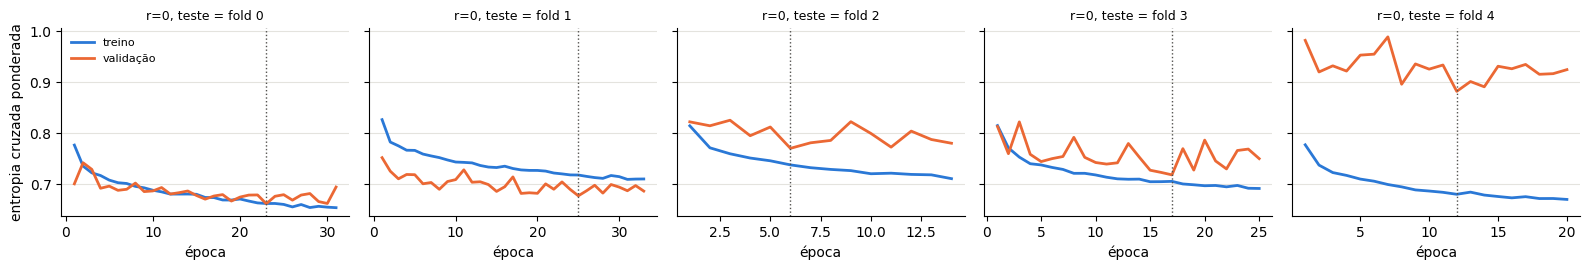

In [4]:
# curvas de aprendizado da primeira repetição treinada (NLL ponderada; treino com augmentation e dropout)
r_curva = int(tab_historico["repeticao"].min())
divs = tab_historico.loc[tab_historico["repeticao"] == r_curva, "fold_teste"].drop_duplicates().to_numpy()
fig, eixos = plt.subplots(1, len(divs), figsize=(3.2 * len(divs), 2.8), squeeze=False, sharey=True)
for ax, f in zip(eixos[0], divs):
    h = tab_historico[(tab_historico.repeticao == r_curva) & (tab_historico.fold_teste == f)]
    ax.plot(h.epoca, h.perda_treino, color="#2a78d6", linewidth=2, label="treino")
    ax.plot(h.epoca, h.perda_validacao, color="#eb6834", linewidth=2, label="validação")
    melhor = tab_resultados[(tab_resultados.repeticao == r_curva) & (tab_resultados.fold_teste == f)]["melhor_epoca"].iloc[0]
    ax.axvline(melhor, color="#52514e", linewidth=1, linestyle=":")
    ax.set_title(f"r={r_curva}, teste = fold {f}", fontsize=9)
    ax.set_xlabel("época")
    ax.grid(axis="y", color="#e4e3de", linewidth=0.8)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
eixos[0][0].set_ylabel("entropia cruzada ponderada")
eixos[0][0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(PASTA_SAIDA, "curvas_aprendizado.png"), dpi=130)
plt.show()

## 3. Resumo da CNN

Média e desvio-padrão entre as divisões (teste), com as mesmas métricas do `1_baselines`.

In [5]:
metricas = ["acuracia_balanceada", "acuracia_global", "kappa", "nll_balanceado", "brier_balanceado", "ece",
            "acuracia_interior", "acuracia_borda"]
resumo = tab_resultados.groupby("versao")[metricas].agg(["mean", "std"])
resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
resumo["n_divisoes"] = tab_resultados.groupby("versao").size()
resumo.to_csv(os.path.join(PASTA_SAIDA, "resumo_cnn.csv"))
tabela = pd.DataFrame(index=resumo.index)
for mt in metricas:
    tabela[mt] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(resumo[f"{mt}_mean"], resumo[f"{mt}_std"])]
tabela["n_divisoes"] = resumo["n_divisoes"]
display(tabela)
bruto = tab_resultados[tab_resultados["versao"] == "bruto"]
print("Acurácia do produtor:", {s: round(bruto[f"AP_{s}"].mean(), 3) for s in SIGLAS})
print("Acurácia do usuário: ", {s: round(bruto[f"AU_{s}"].mean(), 3) for s in SIGLAS})
print(f"Melhor época: média {bruto['melhor_epoca'].mean():.1f} (de {bruto['melhor_epoca'].min()} a {bruto['melhor_epoca'].max()}) | "
      f"temperatura: média {tab_resultados.loc[tab_resultados.versao == 'calibrado', 'T'].mean():.2f}")

,acuracia_balanceada,acuracia_global,kappa,nll_balanceado,brier_balanceado,ece,acuracia_interior,acuracia_borda,n_divisoes
versao,,,,,,,,,
bruto,0.690 ± 0.035,0.681 ± 0.020,0.544 ± 0.027,0.755 ± 0.109,0.419 ± 0.046,0.029 ± 0.017,0.755 ± 0.021,0.457 ± 0.025,5
calibrado,0.690 ± 0.035,0.681 ± 0.020,0.544 ± 0.027,0.758 ± 0.107,0.421 ± 0.045,0.040 ± 0.019,0.755 ± 0.021,0.457 ± 0.025,5


Acurácia do produtor: {'F': np.float64(0.83), 'VS': np.float64(0.527), 'PA': np.float64(0.667), 'AG': np.float64(0.736)}
Acurácia do usuário:  {'F': np.float64(0.764), 'VS': np.float64(0.577), 'PA': np.float64(0.712), 'AG': np.float64(0.543)}
Melhor época: média 16.6 (de 6 a 25) | temperatura: média 1.09


## 4. Comparação com os baselines

Junta os resultados da CNN com os do `1_baselines`, **só nas divisões em que a CNN foi treinada**. A comparação pareada usa o RF com contexto da **mesma janela** do patch da CNN (`RF_contexto_5x5` para `TAMANHO_PATCH = 5`, e assim por diante): diferença positiva na acurácia e negativa na NLL favorecem a CNN.

Os folds do Pará são a fase de desenvolvimento; a avaliação final é na área de estudo (`4_cmap`), que não está em nenhum fold.

In [6]:
arq_base = os.path.join(PASTA_BASELINES, "resultados_baselines.csv")
if not os.path.exists(arq_base):
    print(f"{arq_base} não encontrado: comparação não calculada")
    todos = tab_resultados.copy()
else:
    base = pd.read_csv(arq_base)
    divs = set(map(tuple, tab_resultados[["repeticao", "fold_teste"]].drop_duplicates().to_numpy()))
    base = base[[(a, b) in divs for a, b in zip(base.repeticao, base.fold_teste)]]
    todos = pd.concat([tab_resultados, base], ignore_index=True)
    ordem_clf = ["MaxVer", "RF"] + sorted(c_ for c_ in base["classificador"].unique() if c_.startswith("RF_contexto")) + ["CNN"]
    resumo_comp = todos.groupby(["classificador", "versao"])[metricas].mean()
    resumo_comp = resumo_comp.sort_index(key=lambda s: s.map({n: i for i, n in enumerate(ordem_clf)}) if s.name == "classificador" else s)
    resumo_comp.to_csv(os.path.join(PASTA_SAIDA, "comparacao_classificadores.csv"))
    display(resumo_comp.round(3))

    ref = f"RF_contexto_{TAMANHO_PATCH}x{TAMANHO_PATCH}"
    if ref in set(base["classificador"]):
        chave = ["repeticao", "fold_teste"]
        linhas = []
        for versao in ("bruto", "calibrado"):
            a = tab_resultados[tab_resultados.versao == versao].set_index(chave)
            b = base[(base.classificador == ref) & (base.versao == versao)].set_index(chave)
            comuns = a.index.intersection(b.index)
            for mt in ("acuracia_balanceada", "nll_balanceado", "ece", "acuracia_borda", "acuracia_interior"):
                d = a.loc[comuns, mt] - b.loc[comuns, mt]
                melhor = (d > 0) if mt.startswith("acuracia") else (d < 0)
                linhas.append({"versao": versao, "metrica": mt, "dif_media": d.mean(), "dif_min": d.min(),
                               "dif_max": d.max(), "divisoes_cnn_melhor": f"{int(melhor.sum())}/{len(d)}"})
        pareada = pd.DataFrame(linhas)
        pareada.to_csv(os.path.join(PASTA_SAIDA, f"comparacao_pareada_{ref}.csv"), index=False)
        print(f"\nCNN − {ref}, divisão a divisão:")
        display(pareada.round(3))
    else:
        print(f"{ref} não está nos resultados do 1_baselines: comparação pareada não calculada")

acuracia_balanceada  acuracia_global  kappa  \
classificador   versao                                                   
MaxVer          bruto                    0.576            0.569  0.384   
                calibrado                0.576            0.569  0.384   
RF              bruto                    0.606            0.624  0.456   
                calibrado                0.606            0.624  0.456   
RF_contexto_5x5 bruto                    0.665            0.685  0.546   
                calibrado                0.665            0.685  0.546   
RF_contexto_7x7 bruto                    0.675            0.696  0.560   
                calibrado                0.675            0.696  0.560   
RF_contexto_9x9 bruto                    0.680            0.701  0.568   
                calibrado                0.680            0.701  0.568   
CNN             bruto                    0.690            0.681  0.544   
                calibrado                0.690            0.681  0.544   

                           nll_balanceado  brier_balanceado    ece  \
classificador   versao                                               
MaxVer          bruto               1.195             0.568  0.143   
                calibrado           1.003             0.545  0.068   
RF              bruto               1.003             0.524  0.055   
                calibrado           0.968             0.524  0.047   
RF_contexto_5x5 bruto               0.846             0.452  0.029   
                calibrado           0.844             0.456  0.046   
RF_contexto_7x7 bruto               0.830             0.442  0.029   
                calibrado           0.828             0.446  0.048   
RF_contexto_9x9 bruto               0.817             0.434  0.028   
                calibrado           0.815             0.439  0.049   
CNN             bruto               0.755             0.419  0.029   
                calibrado           0.758             0.421  0.040   

                           acuracia_interior  acuracia_borda  
classificador   versao                                        
MaxVer          bruto                  0.649           0.331  
                calibrado              0.649           0.331  
RF              bruto                  0.697           0.405  
                calibrado              0.697           0.405  
RF_contexto_5x5 bruto                  0.757           0.469  
                calibrado              0.757           0.469  
RF_contexto_7x7 bruto                  0.767           0.481  
                calibrado              0.767           0.481  
RF_contexto_9x9 bruto                  0.771           0.489  
                calibrado              0.771           0.489  
CNN             bruto                  0.755           0.457  
                calibrado              0.755           0.457


CNN − RF_contexto_5x5, divisão a divisão:


,versao,metrica,dif_media,dif_min,dif_max,divisoes_cnn_melhor
0,bruto,acuracia_balanceada,0.025,0.009,0.054,5/5
1,bruto,nll_balanceado,-0.092,-0.132,-0.015,5/5
2,bruto,ece,-0.000,-0.005,0.004,3/5
3,bruto,acuracia_borda,-0.012,-0.038,0.009,1/5
4,bruto,acuracia_interior,-0.002,-0.019,0.016,2/5
5,calibrado,acuracia_balanceada,0.025,0.009,0.054,5/5
6,calibrado,nll_balanceado,-0.086,-0.130,-0.029,5/5
7,calibrado,ece,-0.006,-0.047,0.023,2/5
8,calibrado,acuracia_borda,-0.012,-0.038,0.009,1/5
9,calibrado,acuracia_interior,-0.002,-0.019,0.016,2/5


## 5. Previsão fora do fold (repetição 0)

Como no `1_baselines`: juntando os testes dos 5 folds da repetição 0, cada patch tem uma previsão feita por um modelo que não viu a órbita-ponto dele. A figura compara a acurácia por distância à borda da CNN com a dos baselines.

Matriz de confusão (linhas = referência TerraClass, colunas = previsto):
previsto        F     VS     PA    AG
referencia                           
F           28020   5042    638    73
VS           7813  16646   6451   647
PA            899   6795  20202  2286
AG             29    428   1015  3659

Acurácia balanceada por ano: {2008: 0.684, 2010: 0.687}

Acurácia por distância à borda:
dist_borda_px        1      2      3      4      5
classificador                                     
CNN              0.457  0.570  0.643  0.687  0.836
MaxVer           0.331  0.394  0.465  0.509  0.770
RF               0.405  0.511  0.583  0.645  0.776
RF_contexto_5x5  0.469  0.574  0.646  0.689  0.837
RF_contexto_7x7  0.482  0.588  0.653  0.699  0.846
RF_contexto_9x9  0.490  0.593  0.654  0.701  0.851


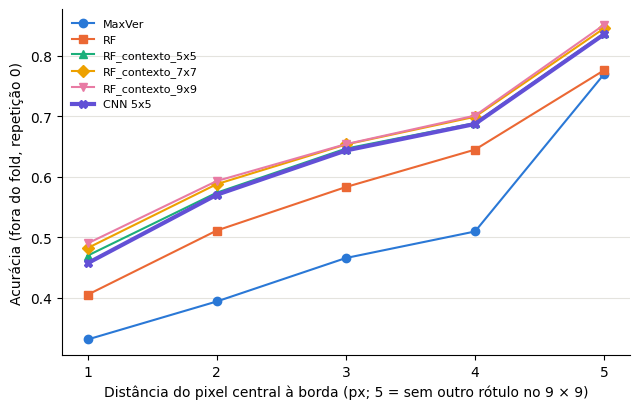

In [7]:
arqs_r0 = [os.path.join(PASTA_SAIDA, f"probs_cnn_r0_f{f}.npz") for f in range(N_FOLDS)]
if not all(os.path.exists(a) for a in arqs_r0):
    print("A repetição 0 não está completa: a previsão fora do fold não foi calculada.")
else:
    posicao = pd.Index(meta["id"])
    pred = np.full(len(meta), -1)
    for a in arqs_r0:
        with np.load(a) as z:
            pred[posicao.get_indexer(z["id_teste"])] = z["logp_CNN_bruto"].argmax(axis=1)
    if (pred < 0).any():
        raise ValueError("Há patches sem previsão nos testes da repetição 0")
    anos_m, dist_m = meta["ano"].to_numpy(), meta["dist_borda_px"].to_numpy()
    tab_cm = pd.DataFrame([{"classificador": "CNN", "referencia": SIGLAS[kr], "previsto": SIGLAS[kp],
                            "n": int(((y_todos == kr) & (pred == kp)).sum())} for kr in range(K) for kp in range(K)])
    tab_ano = pd.DataFrame([{"classificador": "CNN", "ano": int(ano),
                             "acuracia_balanceada": np.mean([(pred[(anos_m == ano) & (y_todos == k)] == k).mean()
                                                             for k in range(K) if ((anos_m == ano) & (y_todos == k)).any()]),
                             "acuracia_global": (pred[anos_m == ano] == y_todos[anos_m == ano]).mean(),
                             "n": int((anos_m == ano).sum())} for ano in sorted(np.unique(anos_m))])
    tab_dist = pd.DataFrame([{"classificador": "CNN", "dist_borda_px": int(d),
                              "acuracia": (pred[dist_m == d] == y_todos[dist_m == d]).mean(), "n": int((dist_m == d).sum())}
                             for d in sorted(np.unique(dist_m))])
    tab_cm.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_confusao.csv"), index=False)
    tab_ano.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_por_ano.csv"), index=False)
    tab_dist.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_por_dist_borda.csv"), index=False)
    print("Matriz de confusão (linhas = referência TerraClass, colunas = previsto):")
    print(tab_cm.pivot(index="referencia", columns="previsto", values="n").reindex(index=SIGLAS, columns=SIGLAS).to_string())
    print("\nAcurácia balanceada por ano:", {int(a): round(v, 3) for a, v in zip(tab_ano.ano, tab_ano.acuracia_balanceada)})

    # acurácia por distância à borda: CNN x baselines (mesmos patches, repetição 0)
    arq_dist_base = os.path.join(PASTA_BASELINES, "fora_do_fold_r0_por_dist_borda.csv")
    dist_todos = tab_dist.copy()
    if os.path.exists(arq_dist_base):
        dist_todos = pd.concat([pd.read_csv(arq_dist_base), tab_dist], ignore_index=True)
    tab_d = dist_todos.pivot(index="classificador", columns="dist_borda_px", values="acuracia")
    print("\nAcurácia por distância à borda:")
    print(tab_d.round(3).to_string())

    CORES = {"MaxVer": "#2a78d6", "RF": "#eb6834", "RF_contexto_5x5": "#1baf7a", "RF_contexto_7x7": "#eda100",
             "RF_contexto_9x9": "#e87ba4", "CNN": "#6250d6"}
    MARCADORES = {"MaxVer": "o", "RF": "s", "RF_contexto_5x5": "^", "RF_contexto_7x7": "D", "RF_contexto_9x9": "v", "CNN": "X"}
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for nome in [n for n in CORES if n in tab_d.index]:
        ax.plot(tab_d.columns, tab_d.loc[nome], color=CORES[nome], marker=MARCADORES[nome], markersize=6,
                linewidth=3 if nome == "CNN" else 1.5, label=f"CNN {TAMANHO_PATCH}x{TAMANHO_PATCH}" if nome == "CNN" else nome)
    ax.set_xticks(list(tab_d.columns))
    ax.set_xlabel("Distância do pixel central à borda (px; 5 = sem outro rótulo no 9 × 9)")
    ax.set_ylabel("Acurácia (fora do fold, repetição 0)")
    ax.grid(axis="y", color="#e4e3de", linewidth=0.8)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(PASTA_SAIDA, "acuracia_dist_borda.png"), dpi=130)
    plt.show()

## 6. Comparação de experimentos (validação)

Lê o `resultados_cnn.csv` de cada subpasta de `PASTA_MAE` e compara as configurações **pela validação da repetição 0** (NLL balanceada usada na parada antecipada e acurácia balanceada da validação). A segunda tabela mostra a diferença **pareada** em relação a `EXPERIMENTO_REFERENCIA`, fold a fold (mesmas divisões). Diferença negativa na NLL é melhora; `folds_melhores` conta em quantos dos 5 folds o experimento venceu a referência.

Regra prática: com 5 folds e a variação observada entre órbitas-ponto, só vale adotar uma mudança que melhore a média **e** vença em pelo menos 4 dos 5 folds. A configuração escolhida é então rodada nas 5 repetições.

In [8]:
tabs = []
for arq in sorted(glob.glob(os.path.join(PASTA_MAE, "*", "resultados_cnn.csv"))):
    t = pd.read_csv(arq)
    t = t[(t.versao == "bruto") & (t.repeticao == 0)].copy()
    t["experimento"] = os.path.basename(os.path.dirname(arq))
    tabs.append(t[["experimento", "fold_teste", "nll_validacao", "acur_bal_validacao", "melhor_epoca"]])
exp = pd.concat(tabs, ignore_index=True)
medias = exp.groupby("experimento").agg(n_folds=("fold_teste", "size"), nll_val=("nll_validacao", "mean"),
                                        nll_val_dp=("nll_validacao", "std"), acur_bal_val=("acur_bal_validacao", "mean"),
                                        melhor_epoca=("melhor_epoca", "mean")).sort_values("nll_val")
display(medias.round(3))

if EXPERIMENTO_REFERENCIA in set(exp.experimento):
    ref_exp = exp[exp.experimento == EXPERIMENTO_REFERENCIA].set_index("fold_teste")
    pares = []
    for nome, t in exp[exp.experimento != EXPERIMENTO_REFERENCIA].groupby("experimento"):
        t = t.set_index("fold_teste")
        comuns = t.index.intersection(ref_exp.index)
        d_nll = t.loc[comuns, "nll_validacao"] - ref_exp.loc[comuns, "nll_validacao"]
        d_acc = t.loc[comuns, "acur_bal_validacao"] - ref_exp.loc[comuns, "acur_bal_validacao"]
        pares.append({"experimento": nome, "n_folds": len(comuns), "dif_nll_val": d_nll.mean(), "dif_nll_dp": d_nll.std(),
                      "dif_acur_bal_val": d_acc.mean(), "folds_melhores": int((d_nll < 0).sum())})
    if pares:
        display(pd.DataFrame(pares).sort_values("dif_nll_val").round(3))
else:
    print(f'Rode primeiro o experimento "{EXPERIMENTO_REFERENCIA}" para ter a comparação pareada.')

,n_folds,nll_val,nll_val_dp,acur_bal_val,melhor_epoca
experimento,,,,,
patch5,5,0.742,0.089,0.692,16.6


## 7. Saídas

| Arquivo | Conteúdo |
|---|---|
| `configuracao.json` | parâmetros do experimento (protege a pasta contra mistura de experimentos) |
| `modelo_rR_fF.pt` | pesos do melhor modelo, temperatura, classes, bandas e tamanho do patch (usados no `3_inferencia`) |
| `probs_cnn_rR_fF.npz` | log-probabilidades do teste (`id_teste`, `logp_CNN_<bruto\|calibrado>`) |
| `resultados_cnn.csv` | uma linha por divisão e versão: métricas no teste, temperatura, época e critérios da validação |
| `historico_treino.csv`, `curvas_aprendizado.png` | perdas de treino e validação por época |
| `resumo_cnn.csv`, `comparacao_classificadores.csv`, `comparacao_pareada_RF_contexto_*.csv` | resumo e comparação com os baselines |
| `fora_do_fold_r0_*.csv`, `acuracia_dist_borda.png` | previsão fora do fold da repetição 0 |

In [9]:
total = sum(os.path.getsize(os.path.join(PASTA_SAIDA, a)) for a in os.listdir(PASTA_SAIDA))
print(f"Saídas em {PASTA_SAIDA}: {len(os.listdir(PASTA_SAIDA))} arquivos, {total / 1e6:.0f} MB")

Saídas em C:\cmap_ftl\terraclass\resultados\2_treino_cnn\patch5: 21 arquivos, 4 MB
